In [ ]:
import pandas as pd


In [ ]:
import numpy as np


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import pandas as pd

df = pd.read_csv('/content/Dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Number of Rows:", df.shape[0])

Number of Rows: 8790


In [ ]:
print("Number of Columns:", df.shape[1])

Number of Columns: 10


In [ ]:
df.head(10)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [ ]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [ ]:
print(df.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [ ]:
df.describe(include='all')   #statistical summary

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790
unique,8790,2,8787,4528,86,1713,NaN,14,220,513
top,s1,Movie,9-Feb,Not Given,United States,1/1/2020,NaN,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN


In [ ]:
#  all available columns
for column in df.columns:
    print(column)

show_id
type
title
director
country
date_added
release_year
rating
duration
listed_in


In [ ]:
# Display column names and data types
column_details = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.values,
    'Missing Values': df.isnull().sum().values,
    'Unique Values': df.nunique().values
})

display(column_details)

,Column Name,Data Type,Missing Values,Unique Values
0,show_id,object,0,8790
1,type,object,0,2
2,title,object,0,8787
3,director,object,0,4528
4,country,object,0,86
5,date_added,object,0,1713
6,release_year,int64,0,74
7,rating,object,0,14
8,duration,object,0,220
9,listed_in,object,0,513


In [ ]:
# Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.sort_values(ascending=False))

Missing Value Percentage:
show_id         0.0
type            0.0
title           0.0
director        0.0
country         0.0
date_added      0.0
release_year    0.0
rating          0.0
duration        0.0
listed_in       0.0
dtype: float64


In [ ]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing text values with empty strings
for column in df.select_dtypes(include=['object', 'string']).columns:
    df[column] = df[column].fillna('')

print("\nMissing text values handled successfully!")

Missing values before cleaning:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Missing text values handled successfully!


In [ ]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates after cleaning:", df.duplicated().sum())   #remove duplicates


Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [ ]:
import re                      #text data cleaning

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

print("Text cleaning function created successfully!")

Text cleaning function created successfully!


In [ ]:
print(df.columns.tolist())

['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [ ]:
title_column = 'title'

feature_columns = [
    'type',
    'director',
    'country',
    'rating',
    'listed_in'
]

print("Selected title column:", title_column)
print("Selected features:", feature_columns)

Selected title column: title
Selected features: ['type', 'director', 'country', 'rating', 'listed_in']


In [ ]:
# Combine selected content features
df['combined_features'] = df[feature_columns].apply(
    lambda row: ' '.join(
        clean_text(value) for value in row
        if str(value).strip()
    ),
    axis=1
)

print("Content features combined successfully!")

display(df[[title_column, 'combined_features']].head())

Content features combined successfully!


,title,combined_features
0,Dick Johnson Is Dead,movie kirsten johnson united states pg 13 docu...
1,Ganglands,tv show julien leclercq france tv ma crime tv ...
2,Midnight Mass,tv show mike flanagan united states tv ma tv d...
3,Confessions of an Invisible Girl,movie bruno garotti brazil tv pg children fami...
4,Sankofa,movie haile gerima united states tv ma dramas ...


In [ ]:
print("ACTUAL DATASET COLUMNS:")

for i, col in enumerate(df.columns):
    print(i + 1, repr(col))

ACTUAL DATASET COLUMNS:
1 'show_id'
2 'type'
3 'title'
4 'director'
5 'country'
6 'date_added'
7 'release_year'
8 'rating'
9 'duration'
10 'listed_in'
11 'combined_features'


In [ ]:
#check available text column

print("TEXT COLUMNS AVAILABLE:")

print(df.select_dtypes(include=['object', 'string']).columns.tolist())

TEXT COLUMNS AVAILABLE:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'combined_features']


In [ ]:
# Select the title column
title_column = 'title'

# Select available content-related features
feature_columns = [
    'type',
    'director',
    'country',
    'rating',
    'listed_in'
]

print("Title column:", title_column)
print("Selected features:", feature_columns)

Title column: title
Selected features: ['type', 'director', 'country', 'rating', 'listed_in']


In [ ]:
# Fill missing values in selected columns
for column in [title_column] + feature_columns:
    df[column] = df[column].fillna('').astype(str)

print("Missing values handled successfully!")

Missing values handled successfully!


In [ ]:
#check available

print("Checking selected columns:")

for col in feature_columns:
    if col in df.columns:
        print(col, " - Available")
    else:
        print(col, " - Not found")

Checking selected columns:
type  - Available
director  - Available
country  - Available
rating  - Available
listed_in  - Available


In [ ]:
df['combined_features'] = df[feature_columns].apply(
    lambda row: ' '.join(
        clean_text(value) for value in row
        if str(value).strip()
    ),
    axis=1
)

print("Content features combined successfully!")

display(df[['title', 'combined_features']].head(10))

Content features combined successfully!


,title,combined_features
0,Dick Johnson Is Dead,movie kirsten johnson united states pg 13 docu...
1,Ganglands,tv show julien leclercq france tv ma crime tv ...
2,Midnight Mass,tv show mike flanagan united states tv ma tv d...
3,Confessions of an Invisible Girl,movie bruno garotti brazil tv pg children fami...
4,Sankofa,movie haile gerima united states tv ma dramas ...
5,The Great British Baking Show,tv show andy devonshire united kingdom tv 14 b...
6,The Starling,movie theodore melfi united states pg 13 comed...
7,Motu Patlu in the Game of Zones,movie suhas kadav india tv y7 children family ...
8,Je Suis Karl,movie christian schwochow germany tv ma dramas...
9,Motu Patlu in Wonderland,movie suhas kadav india tv y7 children family ...


In [ ]:
title_column = 'title'

feature_columns = [
    'type',
    'director',
    'country',
    'rating',
    'listed_in'
]

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

#import TF-IDF

TF-IDF imported successfully!


In [ ]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

tfidf_matrix = tfidf.fit_transform(
    df['combined_features']
)

print("TF-IDF Vectorization Completed!")
print("Matrix Shape:", tfidf_matrix.shape)
print("Number of Titles:", len(df))
print("Number of Features:", len(tfidf.get_feature_names_out()))

TF-IDF Vectorization Completed!
Matrix Shape: (8790, 5000)
Number of Titles: 8790
Number of Features: 5000


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(
    tfidf_matrix,
    dense_output=False
)

print("Cosine Similarity Completed!")
print("Similarity Matrix Shape:", similarity_matrix.shape)
#calculate similarities

Cosine Similarity Completed!
Similarity Matrix Shape: (8790, 8790)


In [ ]:
#create reccommendation function
def recommend_titles(title, top_n=10):

    matches = df[
        df['title'].str.lower() == title.lower()
    ]

    if matches.empty:
        print("Title not found!")
        return

    idx = matches.index[0]

    scores = similarity_matrix[idx].toarray().flatten()

    similar_indices = scores.argsort()[::-1]

    similar_indices = [
        i for i in similar_indices if i != idx
    ][:top_n]

    recommendations = df.iloc[similar_indices][
        ['title', 'type', 'director', 'listed_in']
    ].copy()

    recommendations['similarity_score'] = scores[similar_indices]

    return recommendations.reset_index(drop=True)


print("Recommendation engine created successfully!")

Recommendation engine created successfully!


In [ ]:
print(df['title'].head(20).to_list())

['Dick Johnson Is Dead', 'Ganglands', 'Midnight Mass', 'Confessions of an Invisible Girl', 'Sankofa', 'The Great British Baking Show', 'The Starling', 'Motu Patlu in the Game of Zones', 'Je Suis Karl', 'Motu Patlu in Wonderland', 'Motu Patlu: Deep Sea Adventure', 'Motu Patlu: Mission Moon', '99 Songs (Tamil)', 'Bridgerton - The Afterparty', 'Bling Empire - The Afterparty', 'Cobra Kai - The Afterparty', 'The Circle - The Afterparty', 'Jailbirds New Orleans', 'Crime Stories: India Detectives', 'True: Winter Wishes']


In [ ]:
recommend_titles('Inception', top_n=10)

,title,type,director,listed_in,similarity_score
0,9,Movie,Shane Acker,"Action & Adventure, Independent Movies, Sci-Fi...",0.605833
1,John Carter,Movie,Andrew Stanton,"Action & Adventure, Sci-Fi & Fantasy",0.547561
2,See You Yesterday,Movie,Stefon Bristol,"Dramas, Sci-Fi & Fantasy, Thrillers",0.520426
3,Star Trek: Voyager,TV Show,Not Given,"TV Action & Adventure, TV Sci-Fi & Fantasy",0.517087
4,Star Trek: The Next Generation,TV Show,Not Given,"TV Action & Adventure, TV Sci-Fi & Fantasy",0.517087
5,Dragonheart: Vengeance,Movie,Ivan Silvestrini,"Action & Adventure, Sci-Fi & Fantasy",0.513557
6,Terminator Salvation,Movie,McG,"Action & Adventure, Sci-Fi & Fantasy",0.510731
7,Dragonheart 3: The Sorcerer,Movie,Colin Teague,"Action & Adventure, Sci-Fi & Fantasy",0.507533
8,Star Trek,Movie,J.J. Abrams,"Action & Adventure, Sci-Fi & Fantasy",0.494231
9,The Next Karate Kid,Movie,Christopher Cain,"Action & Adventure, Dramas, Sports Movies",0.492457


In [ ]:
# Check available content types

print("Content Types:")
print(df['type'].value_counts())

# Check missing values
print("\nMissing Values:")
print(df['type'].isnull().sum())

# Check unique categories
print("\nUnique Categories:")
print(df['type'].unique())

Content Types:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Missing Values:
0

Unique Categories:
['Movie' 'TV Show']


In [ ]:
import pandas as pd
import numpy as np

ml_df = df.copy()
ml_df.columns = ml_df.columns.str.strip()

#Select relevant dataset features



# Remove rows without target values
ml_df = ml_df.dropna(subset=['type']).copy()

# Keep only valid target classes
ml_df['type'] = ml_df['type'].astype(str).str.strip()
ml_df = ml_df[ml_df['type'].isin(['Movie', 'TV Show'])].copy()

# Handle missing categorical values
for col in ['country', 'rating', 'listed_in']:
    ml_df[col] = ml_df[col].fillna('Unknown').astype(str)

# Extract year and month
ml_df['date_added'] = pd.to_datetime(
    ml_df['date_added'], errors='coerce'
)

ml_df['added_year'] = ml_df['date_added'].dt.year.fillna(0)
ml_df['added_month'] = ml_df['date_added'].dt.month.fillna(0)

# Select input features
X = ml_df[
    ['country', 'rating', 'listed_in', 'added_year', 'added_month']
]

# Select target variable
y = ml_df['type']

print("Input Features:")
display(X.head())

print("Target Variable:")
print(y.value_counts())

Input Features:


,country,rating,listed_in,added_year,added_month
0,United States,PG-13,Documentaries,2021,9
1,France,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",2021,9
2,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries",2021,9
3,Brazil,TV-PG,"Children & Family Movies, Comedies",2021,9
4,United States,TV-MA,"Dramas, Independent Movies, International Movies",2021,9


Target Variable:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [ ]:
#Encode categorical variables


from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = ['country', 'rating', 'listed_in']
numerical_features = ['added_year', 'added_month']

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features),

        ('numerical',
         'passthrough',
         numerical_features)
    ]
)

print("Categorical encoding setup completed!")

Categorical encoding setup completed!


In [ ]:
#Train classification model

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 7032
Testing records: 1758


In [ ]:
#now train the model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'Linear SVM': LinearSVC(
        class_weight='balanced',
        random_state=42,
        max_iter=5000
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Linear SVM trained successfully!


In [ ]:
#Evaluate prediction performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'Balanced Accuracy': balanced_accuracy_score(
            y_test, y_pred
        )
    })

    print("\nModel:", name)
    print(classification_report(
        y_test, y_pred,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

display(results_df.round(4))


Model: Logistic Regression
              precision    recall  f1-score   support

       Movie       1.00      0.98      0.99      1225
     TV Show       0.96      1.00      0.98       533

    accuracy                           0.99      1758
   macro avg       0.98      0.99      0.98      1758
weighted avg       0.99      0.99      0.99      1758


Model: Decision Tree
              precision    recall  f1-score   support

       Movie       1.00      0.99      0.99      1225
     TV Show       0.99      0.99      0.99       533

    accuracy                           0.99      1758
   macro avg       0.99      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758


Model: Random Forest
              precision    recall  f1-score   support

       Movie       0.99      0.98      0.98      1225
     TV Show       0.96      0.97      0.97       533

    accuracy                           0.98      1758
   macro avg       0.97      0.98      0.98      1758
we

,Model,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,Logistic Regression,0.9852,0.9858,0.9852,0.9853,0.9889
1,Decision Tree,0.9926,0.9926,0.9926,0.9926,0.9920
2,Random Forest,0.9790,0.9791,0.9790,0.9790,0.9769
3,Linear SVM,0.9966,0.9966,0.9966,0.9966,0.9976


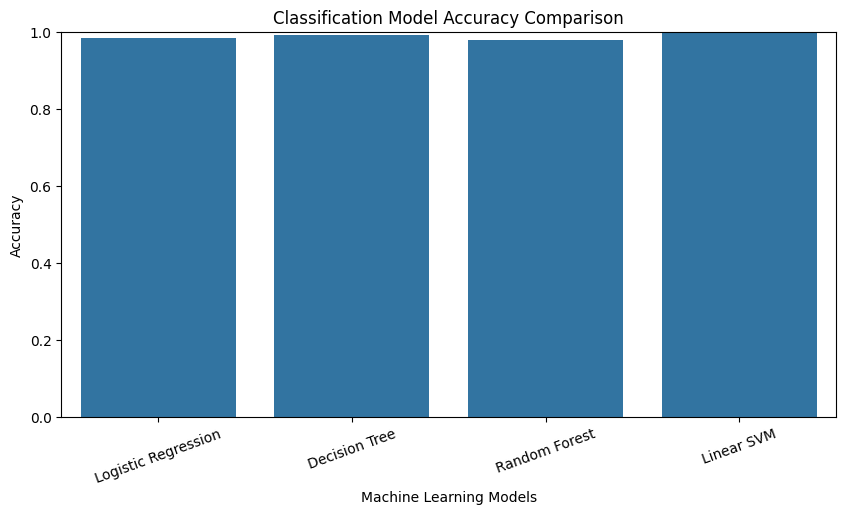

In [ ]:
#Compare model accuracy
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Classification Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

In [ ]:
#Find the best-performing model
best_result = results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]

print("BEST CLASSIFICATION MODEL")
print("-------------------------")
print("Model:", best_result['Model'])
print("Accuracy:", round(best_result['Accuracy'] * 100, 2), "%")
print("Precision:", round(best_result['Precision'] * 100, 2), "%")
print("Recall:", round(best_result['Recall'] * 100, 2), "%")
print("F1 Score:", round(best_result['F1 Score'] * 100, 2), "%")

BEST CLASSIFICATION MODEL
-------------------------
Model: Linear SVM
Accuracy: 99.66 %
Precision: 99.66 %
Recall: 99.66 %
F1 Score: 99.66 %


Dataset columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'combined_features']

Missing rating values:
0

Rating category distribution:


,Number of Titles
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


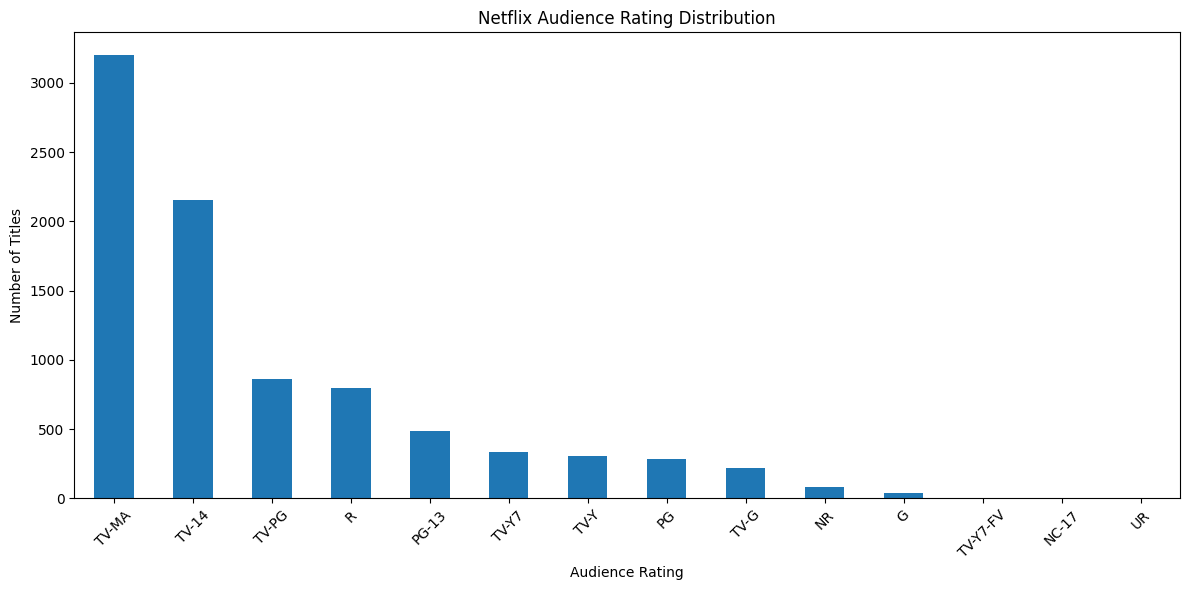

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate dataset for Task 3
rating_df = df.copy()
rating_df.columns = rating_df.columns.str.strip()

# Check available columns
print("Dataset columns:")
print(rating_df.columns.tolist())

# Analyze audience rating categories
print("\nMissing rating values:")
print(rating_df['rating'].isnull().sum())

print("\nRating category distribution:")
display(
    rating_df['rating']
    .value_counts(dropna=False)
    .to_frame('Number of Titles')
)
                                                                     #Examples of Netflix ratings:
                                                                    #- TV-MA – Mature audiences
                                                                    #- TV-14 – Parents strongly cautioned
                                                                    #- TV-PG – Parental guidance suggested
                                                                    #- PG-13 – Parents strongly cautioned
                                                                    #- PG – Parental guidance suggested
                                                                    #- R – Restricted
# Visualize the top 15 rating categories
plt.figure(figsize=(12, 6))

rating_df['rating'].value_counts().head(15).plot(
    kind='bar'
)

plt.title('Netflix Audience Rating Distribution')
plt.xlabel('Audience Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Keep records with a rating
rating_df = rating_df.dropna(subset=['rating']).copy()

# Clean rating text
rating_df['rating'] = rating_df['rating'].astype(str).str.strip()

# Remove invalid values such as duration mistakenly appearing as ratings
invalid_rating = rating_df['rating'].str.match(
    r'^\d+\s*(min|season|seasons)$',
    case=False
)

rating_df = rating_df[~invalid_rating].copy()

# Check rating counts
rating_counts = rating_df['rating'].value_counts()

# Group categories with fewer than 30 records
MIN_RATING_COUNT = 30

rare_ratings = rating_counts[
    rating_counts < MIN_RATING_COUNT
].index

rating_df['rating'] = rating_df['rating'].replace(
    rare_ratings, 'Other'
)

# Handle missing input features
for col in ['type', 'country', 'listed_in']:
    rating_df[col] = rating_df[col].fillna('Unknown').astype(str)

# Extract numerical duration
rating_df['duration_num'] = pd.to_numeric(
    rating_df['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
).fillna(0)

# Extract date information
rating_df['date_added'] = pd.to_datetime(
    rating_df['date_added'],
    errors='coerce'
)

rating_df['added_year'] = rating_df['date_added'].dt.year.fillna(0)
rating_df['added_month'] = rating_df['date_added'].dt.month.fillna(0)

# Select input features
X = rating_df[
    [
        'type',
        'country',
        'listed_in',
        'duration_num',
        'added_year',
        'added_month'
    ]
].copy()

# Target variable
y = rating_df['rating'].copy()

print("Input features:")
display(X.head())

print("\nTarget rating categories:")
print(y.value_counts())

print("\nTotal records:", len(rating_df))
print("Total rating categories:", y.nunique())

Input features:


,type,country,listed_in,duration_num,added_year,added_month
0,Movie,United States,Documentaries,90,2021,9
1,TV Show,France,"Crime TV Shows, International TV Shows, TV Act...",1,2021,9
2,TV Show,United States,"TV Dramas, TV Horror, TV Mysteries",1,2021,9
3,Movie,Brazil,"Children & Family Movies, Comedies",91,2021,9
4,Movie,United States,"Dramas, Independent Movies, International Movies",125,2021,9



Target rating categories:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
G          41
Other      12
Name: count, dtype: int64

Total records: 8790
Total rating categories: 12


In [ ]:
#Split the dataset into training and testing sets:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 7032
Testing records: 1758


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

categorical_features = [
    'type',
    'country',
    'listed_in'
]

numerical_features = [
    'duration_num',
    'added_year',
    'added_month'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

#Train classification models
#compare four classification algorithms:
#1. Logistic Regression
#2. Decision Tree
#3. Random Forest
#4. Linear SVM
#First, encode the categorical features and scale numerical features

In [ ]:
#train the models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'Linear SVM': LinearSVC(
        class_weight='balanced',
        random_state=42,
        max_iter=5000
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Linear SVM trained successfully!


In [ ]:
#Optimize model performance
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import pandas as pd

# Re-extract features and target if not present
if 'X_train' not in globals() or 'y_train' not in globals():
    # Load df if it doesn't exist
    if 'df' not in globals():
        df = pd.read_csv('/content/Dataset.csv')

    # Ensure rating_df is properly set up
    rating_df = df.copy()
    rating_df.columns = rating_df.columns.str.strip()
    rating_df = rating_df.dropna(subset=['rating']).copy()
    rating_df['rating'] = rating_df['rating'].astype(str).str.strip()

    # Filter invalid ratings
    invalid_rating = rating_df['rating'].str.match(r'^\d+\s*(min|season|seasons)$', case=False)
    rating_df = rating_df[~invalid_rating].copy()

    # Group rare categories
    rating_counts = rating_df['rating'].value_counts()
    rare_ratings = rating_counts[rating_counts < 30].index
    rating_df['rating'] = rating_df['rating'].replace(rare_ratings, 'Other')

    # Feature Engineering
    for col in ['type', 'country', 'listed_in']:
        rating_df[col] = rating_df[col].fillna('Unknown').astype(str)

    rating_df['duration_num'] = pd.to_numeric(
        rating_df['duration'].astype(str).str.extract(r'(\d+)')[0],
        errors='coerce'
    ).fillna(0)

    rating_df['date_added'] = pd.to_datetime(rating_df['date_added'], errors='coerce')
    rating_df['added_year'] = rating_df['date_added'].dt.year.fillna(0)
    rating_df['added_month'] = rating_df['date_added'].dt.month.fillna(0)

    X = rating_df[['type', 'country', 'listed_in', 'duration_num', 'added_year', 'added_month']]
    y = rating_df['rating']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

# Ensure preprocessor is defined in this scope
categorical_features = ['type', 'country', 'listed_in']
numerical_features = ['duration_num', 'added_year', 'added_month']

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 20],
    'classifier__min_samples_leaf': [1, 3]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_rf_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Weighted F1 Score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}

Best Cross-Validation Weighted F1 Score:
0.4943


In [ ]:
#Add the optimized model to our model collection:

trained_models['Optimized Random Forest'] = best_rf_model

print("Optimized model added successfully!")

Optimized model added successfully!


In [ ]:
#Evaluate prediction accuracy

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'Weighted F1': f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'Macro F1': f1_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        )
    })

    print("\nModel:", name)
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


Model: Logistic Regression
              precision    recall  f1-score   support

           G       0.10      0.62      0.17         8
          NR       0.09      0.69      0.16        16
       Other       0.00      0.00      0.00         2
          PG       0.36      0.47      0.40        58
       PG-13       0.32      0.47      0.38        98
           R       0.43      0.49      0.46       160
       TV-14       0.52      0.48      0.50       431
        TV-G       0.13      0.39      0.20        44
       TV-MA       0.70      0.38      0.49       641
       TV-PG       0.22      0.18      0.20       172
        TV-Y       0.49      0.61      0.54        61
       TV-Y7       0.53      0.48      0.50        67

    accuracy                           0.42      1758
   macro avg       0.32      0.44      0.33      1758
weighted avg       0.52      0.42      0.44      1758


Model: Decision Tree
              precision    recall  f1-score   support

           G       0.50     

,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Logistic Regression,0.4181,0.5154,0.4181,0.4431,0.3336
1,Decision Tree,0.4340,0.4398,0.4340,0.4360,0.3530
2,Random Forest,0.5154,0.4964,0.5154,0.4991,0.3800
3,Linear SVM,0.4494,0.5007,0.4494,0.4645,0.3458
4,Optimized Random Forest,0.5154,0.4964,0.5154,0.4991,0.3800


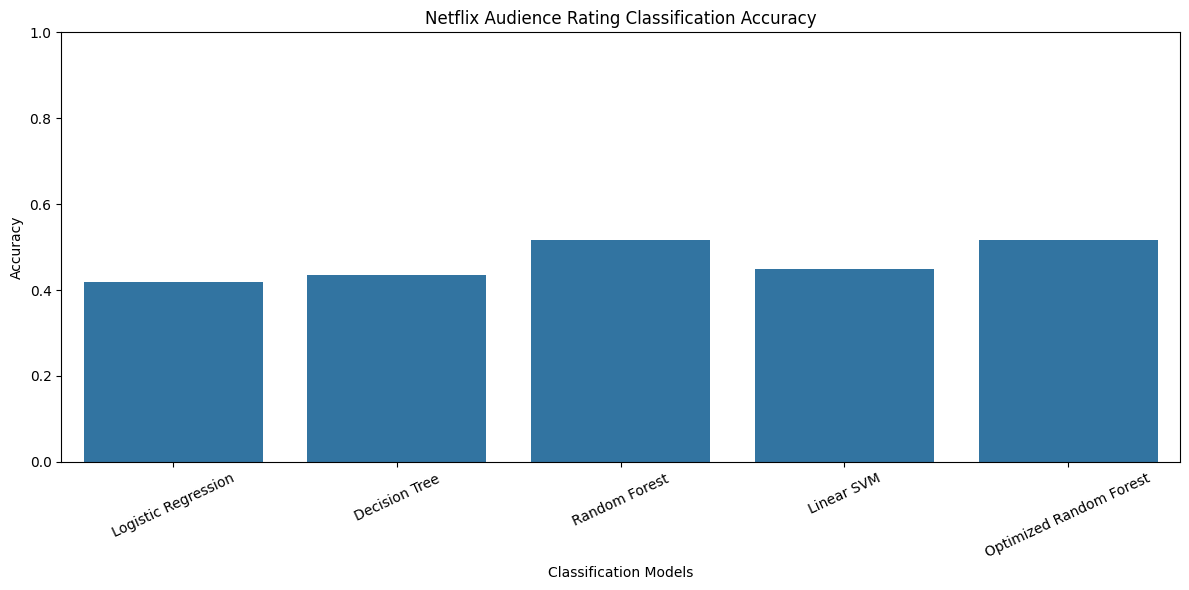

In [ ]:
#Compare model accuracy visually

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Netflix Audience Rating Classification Accuracy')
plt.xlabel('Classification Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
#Find the best model based on weighted F1 score:

best_result = results_df.sort_values(
    by='Weighted F1',
    ascending=False
).iloc[0]

print("BEST MODEL PERFORMANCE")
print("----------------------")
print("Model:", best_result['Model'])
print("Accuracy:", round(best_result['Accuracy'] * 100, 2), "%")
print("Precision:", round(best_result['Precision'] * 100, 2), "%")
print("Recall:", round(best_result['Recall'] * 100, 2), "%")
print("Weighted F1:", round(best_result['Weighted F1'] * 100, 2), "%")
print("Macro F1:", round(best_result['Macro F1'] * 100, 2), "%")

BEST MODEL PERFORMANCE
----------------------
Model: Random Forest
Accuracy: 51.54 %
Precision: 49.64 %
Recall: 51.54 %
Weighted F1: 49.91 %
Macro F1: 38.0 %


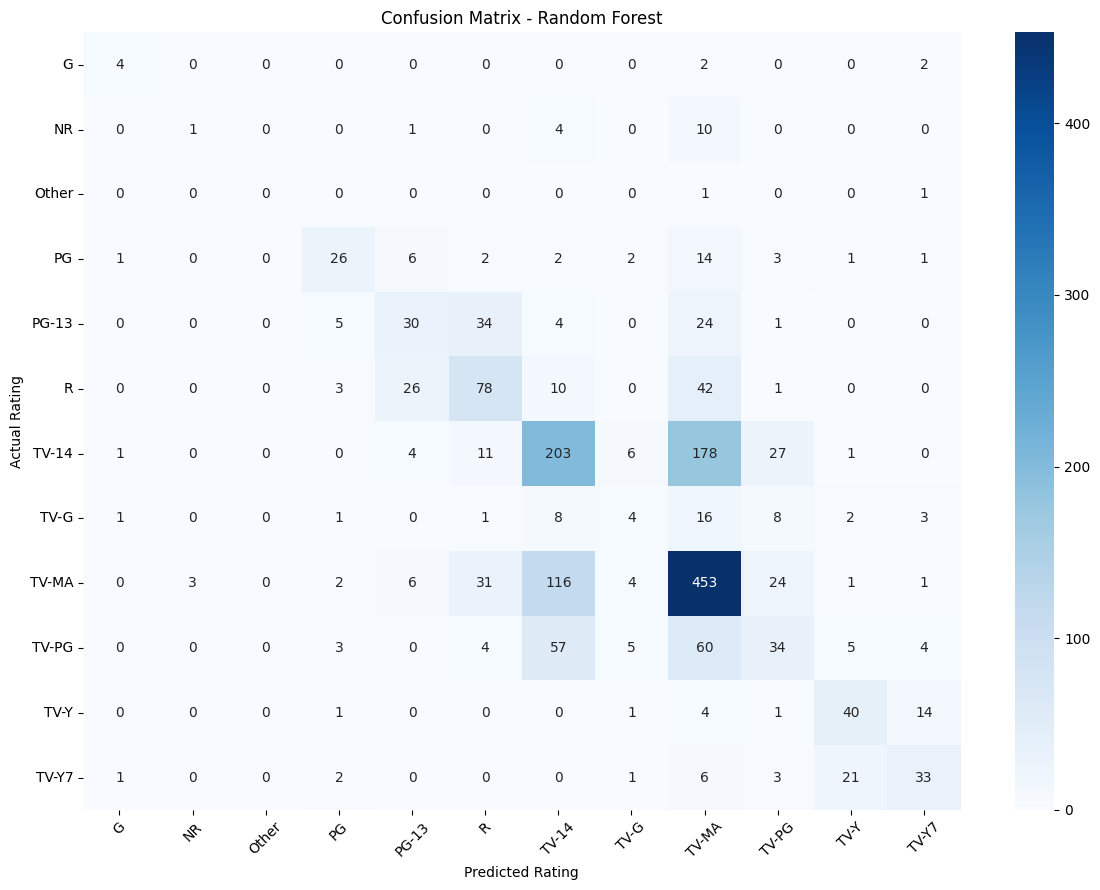

In [ ]:
#Confusion matrix for the best model

from sklearn.metrics import confusion_matrix

best_model_name = best_result['Model']
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#Prepare numerical and categorical features

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate dataset for Task 4
cluster_df = df.copy()
cluster_df.columns = cluster_df.columns.str.strip()

# Check required columns
required = ['type', 'country', 'listed_in', 'duration', 'date_added']
missing = [col for col in required if col not in cluster_df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Handle missing categorical values
for col in ['type', 'country', 'listed_in']:
    cluster_df[col] = cluster_df[col].fillna('Unknown').astype(str)

# Extract numerical duration
cluster_df['duration_num'] = pd.to_numeric(
    cluster_df['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Extract date information
cluster_df['date_added'] = pd.to_datetime(
    cluster_df['date_added'],
    errors='coerce'
)

cluster_df['added_year'] = cluster_df['date_added'].dt.year
cluster_df['added_month'] = cluster_df['date_added'].dt.month

# Fill missing numerical values
numeric_features = ['duration_num', 'added_year', 'added_month']

for col in numeric_features:
    cluster_df[col] = cluster_df[col].fillna(cluster_df[col].median())

# Select features
features = cluster_df[
    [
        'type',
        'country',
        'listed_in',
        'duration_num',
        'added_year',
        'added_month'
    ]
].copy()

print("Selected features:")
display(features.head())

print("\nDataset shape:", features.shape)
print("\nMissing values:")
print(features.isnull().sum())



Selected features:


,type,country,listed_in,duration_num,added_year,added_month
0,Movie,United States,Documentaries,90,2021,9
1,TV Show,France,"Crime TV Shows, International TV Shows, TV Act...",1,2021,9
2,TV Show,United States,"TV Dramas, TV Horror, TV Mysteries",1,2021,9
3,Movie,Brazil,"Children & Family Movies, Comedies",91,2021,9
4,Movie,United States,"Dramas, Independent Movies, International Movies",125,2021,9



Dataset shape: (8790, 6)

Missing values:
type            0
country         0
listed_in       0
duration_num    0
added_year      0
added_month     0
dtype: int64


#Feature	   Feature type    	Preparation





#type	     \\ Categorical	      \\ Encode
#country 	  \\Categorical	       \\Encode
#listed_in	 \\ Categorical	     \\  Encode
#duration   \\	Numerical    	\\Extract  number
#date_added	 \\Numerical   	\\Extract year and month

In [ ]:
#Apply clustering algorithms\

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = ['type', 'country', 'listed_in']
numerical_features = ['duration_num', 'added_year', 'added_month']

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

X_scaled = preprocessor.fit_transform(features)

print("Feature encoding completed!")
print("Encoded dataset shape:", X_scaled.shape)

Feature encoding completed!
Encoded dataset shape: (8790, 604)


In [ ]:
#apply K-Means clustering

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

Clusters: 2, Silhouette Score: 0.2418
Clusters: 3, Silhouette Score: 0.1864
Clusters: 4, Silhouette Score: 0.1612
Clusters: 5, Silhouette Score: 0.1572
Clusters: 6, Silhouette Score: 0.1473


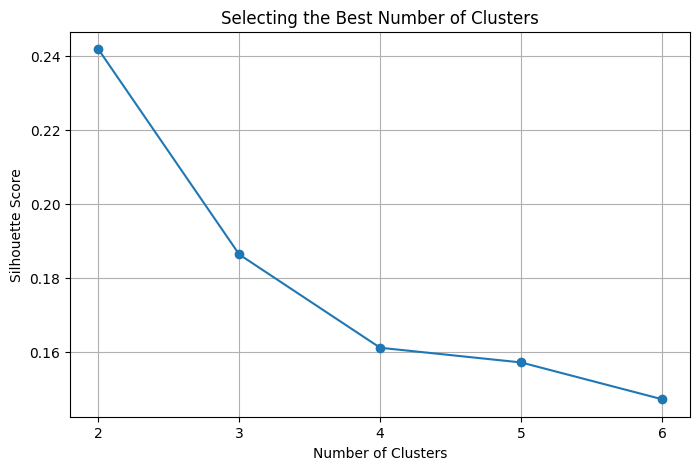

In [ ]:
#Visualize the scores:

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    silhouette_scores,
    marker='o'
)

plt.title('Selecting the Best Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 7))
plt.grid(True)
plt.show()

In [ ]:
#Train the final K-Means model using the best score:

best_k = range(2, 7)[np.argmax(silhouette_scores)]

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_df['Cluster'] = kmeans_model.fit_predict(X_scaled)

print("Selected number of clusters:", best_k)
print("K-Means clustering completed!")

Selected number of clusters: 2
K-Means clustering completed!


In [ ]:
#apply Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

sample_size = min(1000, len(X_scaled))

rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

hierarchical_labels = hierarchical_model.fit_predict(
    X_scaled[sample_indices]
)

cluster_df['Hierarchical_Cluster'] = -1

cluster_df.iloc[
    sample_indices,
    cluster_df.columns.get_loc('Hierarchical_Cluster')
] = hierarchical_labels

print("Hierarchical clustering completed!")
print("Number of sampled records:", sample_size)

Hierarchical clustering completed!
Number of sampled records: 1000


Number of Netflix titles in each cluster:


,Number of Titles
Cluster,
0,6033
1,2757


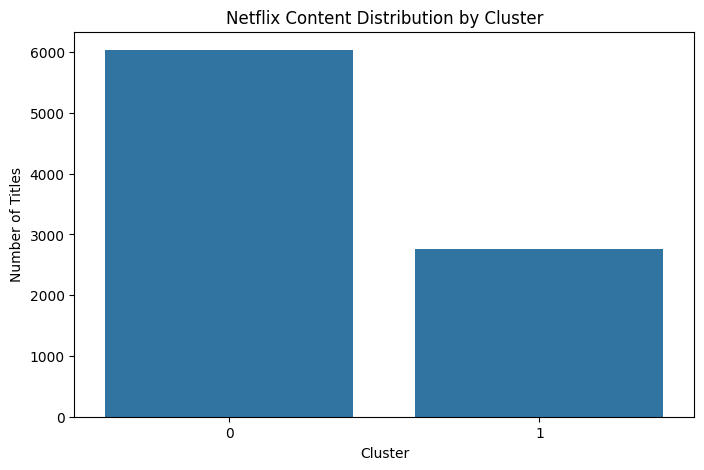

In [ ]:
#Identify content groups

cluster_counts = cluster_df['Cluster'].value_counts().sort_index()

print("Number of Netflix titles in each cluster:")
display(
    cluster_counts.to_frame('Number of Titles')
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title('Netflix Content Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.show()

In [ ]:
#We can also inspect the most common content type and genre in each cluster

def get_mode(series):
    modes = series.mode()
    return modes.iloc[0] if not modes.empty else 'Unknown'

cluster_summary = cluster_df.groupby('Cluster').agg(
    Total_Titles=('Cluster', 'size'),
    Common_Type=('type', get_mode),
    Common_Country=('country', get_mode),
    Common_Genre=('listed_in', get_mode),
    Average_Duration=('duration_num', 'mean'),
    Average_Added_Year=('added_year', 'mean')
).round(2)

display(cluster_summary)

,Total_Titles,Common_Type,Common_Country,Common_Genre,Average_Duration,Average_Added_Year
Cluster,,,,,,
0,6033,Movie,United States,"Dramas, International Movies",100.8,2018.85
1,2757,TV Show,United States,Kids' TV,2.4,2018.93


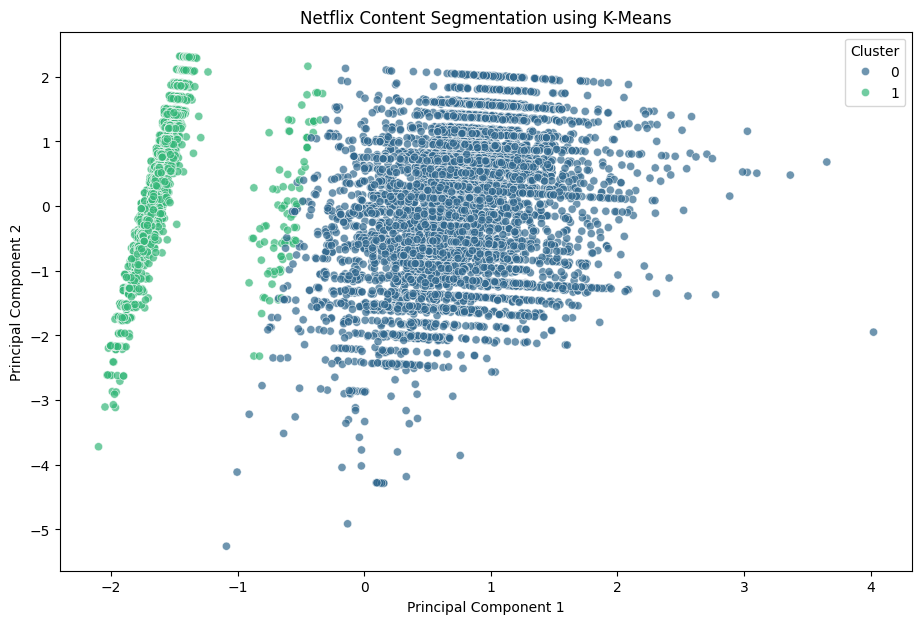

Total variance explained by two components: 48.46 %


In [ ]:
#Visualize clusters

from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'Component 1': X_pca[:, 0],
    'Component 2': X_pca[:, 1],
    'Cluster': cluster_df['Cluster'].values
})

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_df,
    x='Component 1',
    y='Component 2',
    hue='Cluster',
    palette='viridis',
    s=35,
    alpha=0.7
)

plt.title('Netflix Content Segmentation using K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

print(
    "Total variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [ ]:
#Interpret cluster characteristics

for cluster_number in sorted(cluster_df['Cluster'].unique()):

    group = cluster_df[
        cluster_df['Cluster'] == cluster_number
    ]

    print(f"\n========== CLUSTER {cluster_number} ==========")

    print("Total titles:", len(group))

    print("\nContent type distribution:")
    print(group['type'].value_counts())

    print("\nTop 5 countries:")
    print(group['country'].value_counts().head(5))

    print("\nTop 5 genres:")
    print(group['listed_in'].value_counts().head(5))

    print(
        "\nAverage duration value:",
        round(group['duration_num'].mean(), 2)
    )


========== CLUSTER 0 ==========
Total titles: 6033

Content type distribution:
type
Movie    6033
Name: count, dtype: int64

Top 5 countries:
country
United States     2360
India              976
United Kingdom     380
Not Given          242
Canada             177
Name: count, dtype: int64

Top 5 genres:
listed_in
Dramas, International Movies                        360
Documentaries                                       349
Stand-Up Comedy                                     333
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    251
Name: count, dtype: int64

Average duration value: 100.8

========== CLUSTER 1 ==========
Total titles: 2757

Content type distribution:
type
TV Show    2664
Movie        93
Name: count, dtype: int64

Top 5 countries:
country
United States     880
Pakistan          361
United Kingdom    258
Japan             175
South Korea       165
Name: count, dtype: int64

Top 5 genres:
listed_in
Kids' TV        

In [ ]:
#Compare K-Means and Hierarchical Clustering

print("K-MEANS CLUSTER DISTRIBUTION")
print(cluster_df['Cluster'].value_counts().sort_index())

print("\nHIERARCHICAL CLUSTER DISTRIBUTION")
print(
    cluster_df['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)

K-MEANS CLUSTER DISTRIBUTION
Cluster
0    6033
1    2757
Name: count, dtype: int64

HIERARCHICAL CLUSTER DISTRIBUTION
Hierarchical_Cluster
-1    7790
 0     694
 1     306
Name: count, dtype: int64


In [ ]:
#Compare K-Means and Hierarchical Clustering
print("K-MEANS CLUSTER DISTRIBUTION")
print(cluster_df['Cluster'].value_counts().sort_index())

print("\nHIERARCHICAL CLUSTER DISTRIBUTION")
print(
    cluster_df['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)

K-MEANS CLUSTER DISTRIBUTION
Cluster
0    6033
1    2757
Name: count, dtype: int64

HIERARCHICAL CLUSTER DISTRIBUTION
Hierarchical_Cluster
-1    7790
 0     694
 1     306
Name: count, dtype: int64
